# BnSentMix — Model 4 Final Unseen-Test Evaluation

This notebook evaluates the three **already trained and validation-selected** dual-polarity XLM-R checkpoints on the locked unseen test split. It performs **no training, threshold tuning, model selection, or hyperparameter tuning**.

The two saved logits represent positive and negative evidence. Sigmoid probabilities are decoded with the frozen threshold `0.5`: `[1,0] → positive`, `[0,1] → negative`, `[0,0] → neutral`, and `[1,1] → mixed`. Primary reporting is mean ± sample SD across seeds `13, 42, 77`; seed `42` is the predeclared diagnostic seed. H4 remains rejected under its validation rule and is not redefined using test results.

In [1]:
# Cell 1 — Imports and frozen protocol constants
from pathlib import Path
import gc
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import transformers
from IPython.display import display
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_recall_fscore_support
)
from transformers import (
    AutoTokenizer, DataCollatorWithPadding,
    XLMRobertaConfig, XLMRobertaForSequenceClassification
)

EXPECTED_RAW_SHA256 = '148f23eb3dc40c1012a973efec920eaccc39700a74e5bcfb56806b0bf389029d'
EXPECTED_SPLIT_SHA256 = '7be81e52030967319d43ddc1e1feaf9817f9c3011a9b914265c34b5ce0ab8ec5'
EXPECTED_TEST_ROWS = 2973
LABELS = [0, 1, 2, 3]
LABEL_NAMES = {0: 'positive', 1: 'negative', 2: 'neutral', 3: 'mixed'}
MIXED_LABEL = 3
TARGET_MAP = {0: [1, 0], 1: [0, 1], 2: [0, 0], 3: [1, 1]}
EVIDENCE_NAMES = ['positive_evidence', 'negative_evidence']
EVIDENCE_THRESHOLD = 0.5
RUN_SEEDS = [13, 42, 77]
REFERENCE_SEED = 42
MAX_LENGTH = 128
EVAL_BATCH_SIZE = 32

DATA_PATH = Path('/kaggle/input/datasets/olidopu/bnsentmix/dataset.csv')
OUTPUT_DIR = Path('/kaggle/working/bnsentmix_model4_final_test')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('PyTorch:', torch.__version__)
print('Transformers:', transformers.__version__)
print('Device:', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU')
print('Frozen evidence threshold:', EVIDENCE_THRESHOLD)
print('Output directory:', OUTPUT_DIR)

PyTorch: 2.10.0+cpu
Transformers: 5.0.0
Device: CPU
Frozen evidence threshold: 0.5
Output directory: /kaggle/working/bnsentmix_model4_final_test


In [2]:
# Cell 2 — Locate Model 4 artifacts and verify experiment identity
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

preferred_model_dir = Path(
    '/kaggle/input/notebooks/olidopu/final-model4/bnsentmix_model4_dual_polarity'
)
if preferred_model_dir.exists():
    MODEL_INPUT_DIR = preferred_model_dir
else:
    candidates = [p.parent for p in Path('/kaggle/input').rglob('experiment_manifest.json')]
    candidates = [p for p in candidates if p.name == 'bnsentmix_model4_dual_polarity']
    if len(candidates) != 1:
        raise FileNotFoundError(f'Expected one saved Model 4 folder, found: {candidates}')
    MODEL_INPUT_DIR = candidates[0]

SPLIT_PATH = MODEL_INPUT_DIR.parent / 'bnsentmix_protocol_2026' / 'bnsentmix_locked_split.csv'
TOKENIZER_DIR = MODEL_INPUT_DIR / 'tokenizer'
MANIFEST_PATH = MODEL_INPUT_DIR / 'experiment_manifest.json'
CHECKPOINTS = {seed: MODEL_INPUT_DIR / f'seed_{seed}' / 'best_state.pt' for seed in RUN_SEEDS}

assert DATA_PATH.exists(), f'Dataset not found: {DATA_PATH}'
assert SPLIT_PATH.exists(), f'Locked split not found: {SPLIT_PATH}'
assert TOKENIZER_DIR.exists(), f'Tokenizer not found: {TOKENIZER_DIR}'
assert MANIFEST_PATH.exists(), f'Experiment manifest not found: {MANIFEST_PATH}'
for seed, path in CHECKPOINTS.items():
    assert path.exists(), f'Seed {seed} checkpoint not found: {path}'
    assert path.stat().st_size > 1_000_000_000, f'Seed {seed} checkpoint appears incomplete.'

with open(MANIFEST_PATH, encoding='utf-8') as handle:
    manifest = json.load(handle)
assert manifest['dataset_sha256'] == EXPECTED_RAW_SHA256
assert manifest['split_sha256'] == EXPECTED_SPLIT_SHA256
assert manifest['run_seeds'] == RUN_SEEDS
assert np.isclose(float(manifest['evidence_threshold']), EVIDENCE_THRESHOLD)
assert manifest['loss'] == 'unweighted binary cross entropy'

raw_sha = sha256_file(DATA_PATH)
split_sha = sha256_file(SPLIT_PATH)
assert raw_sha == EXPECTED_RAW_SHA256, f'Raw dataset checksum mismatch: {raw_sha}'
assert split_sha == EXPECTED_SPLIT_SHA256, f'Locked split checksum mismatch: {split_sha}'

print('Saved Model 4:', MODEL_INPUT_DIR)
print('Locked split verified:', split_sha)
print('Manifest threshold/loss:', manifest['evidence_threshold'], '/', manifest['loss'])
for seed, path in CHECKPOINTS.items():
    print(f'Seed {seed}: {path.name} ({path.stat().st_size / 1024**3:.2f} GiB)')

Saved Model 4: /kaggle/input/notebooks/olidopu/final-model4/bnsentmix_model4_dual_polarity
Locked split verified: 7be81e52030967319d43ddc1e1feaf9817f9c3011a9b914265c34b5ce0ab8ec5
Manifest threshold/loss: 0.5 / unweighted binary cross entropy
Seed 13: best_state.pt (1.04 GiB)
Seed 42: best_state.pt (1.04 GiB)
Seed 77: best_state.pt (1.04 GiB)


In [3]:
# Cell 3 — Load only the sealed test partition
split_df = pd.read_csv(SPLIT_PATH)
required_columns = {'source_row_id', 'group_id', 'text', 'label', 'split'}
assert required_columns.issubset(split_df.columns), (
    f'Missing split columns: {required_columns - set(split_df.columns)}'
)
assert split_df.groupby('group_id')['split'].nunique().max() == 1, 'Group leakage detected.'

test_df = split_df.loc[split_df['split'].eq('test')].copy().reset_index(drop=True)
test_df['label'] = test_df['label'].astype(int)
assert len(test_df) == EXPECTED_TEST_ROWS, f'Expected {EXPECTED_TEST_ROWS} rows, got {len(test_df)}'
assert sorted(test_df['label'].unique().tolist()) == LABELS

distribution = (
    test_df['label'].value_counts().sort_index()
    .rename(index=LABEL_NAMES).rename('support').to_frame()
)
display(distribution)
print('Sealed unseen-test rows:', len(test_df))

,support
label,
positive,768
negative,922
neutral,1030
mixed,253


Sealed unseen-test rows: 2973


In [4]:
# Cell 4 — Frozen evidence mapping and decoding
def labels_to_evidence(labels):
    return np.asarray([TARGET_MAP[int(label)] for label in labels], dtype=np.int64)

def evidence_to_labels(evidence):
    evidence = np.asarray(evidence).astype(int)
    positive_on = evidence[:, 0] == 1
    negative_on = evidence[:, 1] == 1
    labels = np.full(len(evidence), 2, dtype=int)
    labels[positive_on & ~negative_on] = 0
    labels[~positive_on & negative_on] = 1
    labels[positive_on & negative_on] = 3
    return labels

true_evidence = labels_to_evidence(test_df['label'])
assert np.array_equal(evidence_to_labels(true_evidence), test_df['label'].to_numpy())
display(pd.DataFrame([
    {'label': label, 'class_name': LABEL_NAMES[label],
     'positive_target': TARGET_MAP[label][0], 'negative_target': TARGET_MAP[label][1]}
    for label in LABELS
]))

,label,class_name,positive_target,negative_target
0,0,positive,1,0
1,1,negative,0,1
2,2,neutral,0,0
3,3,mixed,1,1


In [5]:
# Cell 5 — Recreate the exact two-output XLM-R architecture and test loader
tokenizer = AutoTokenizer.from_pretrained(
    TOKENIZER_DIR, use_fast=True, local_files_only=True
)
assert tokenizer.vocab_size == 250002, f'Unexpected tokenizer vocabulary: {tokenizer.vocab_size}'

class TestDataset(Dataset):
    def __init__(self, frame):
        self.texts = frame['text'].astype(str).tolist()

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        return tokenizer(
            self.texts[index], truncation=True, max_length=MAX_LENGTH
        )

collator = DataCollatorWithPadding(
    tokenizer=tokenizer, pad_to_multiple_of=8 if DEVICE.type == 'cuda' else None
)
test_loader = DataLoader(
    TestDataset(test_df), batch_size=EVAL_BATCH_SIZE, shuffle=False,
    collate_fn=collator, num_workers=2, pin_memory=(DEVICE.type == 'cuda')
)

def build_model():
    config = XLMRobertaConfig(
        vocab_size=250002, hidden_size=768, num_hidden_layers=12,
        num_attention_heads=12, intermediate_size=3072, hidden_act='gelu',
        hidden_dropout_prob=0.1, attention_probs_dropout_prob=0.1,
        max_position_embeddings=514, type_vocab_size=1,
        initializer_range=0.02, layer_norm_eps=1e-5,
        pad_token_id=1, bos_token_id=0, eos_token_id=2,
        position_embedding_type='absolute', use_cache=True,
        classifier_dropout=None, num_labels=2,
        id2label={0: EVIDENCE_NAMES[0], 1: EVIDENCE_NAMES[1]},
        label2id={EVIDENCE_NAMES[0]: 0, EVIDENCE_NAMES[1]: 1},
        problem_type='multi_label_classification'
    )
    return XLMRobertaForSequenceClassification(config)

print('Tokenizer loaded locally. Test batches:', len(test_loader))

Tokenizer loaded locally. Test batches: 93


In [6]:
# Cell 6 — Metric and Model 4 checkpoint helpers
def load_exact_state(path):
    try:
        payload = torch.load(path, map_location='cpu', weights_only=True)
    except TypeError:
        payload = torch.load(path, map_location='cpu')
    assert isinstance(payload, dict) and 'model_state_dict' in payload, (
        f'Unexpected Model 4 checkpoint format: {path}'
    )
    return payload['model_state_dict']

def sigmoid_numpy(logits):
    logits = np.clip(np.asarray(logits), -50, 50)
    return 1.0 / (1.0 + np.exp(-logits))

def decode_logits(logits):
    probabilities = sigmoid_numpy(logits)
    evidence_predictions = (probabilities >= EVIDENCE_THRESHOLD).astype(int)
    class_predictions = evidence_to_labels(evidence_predictions)
    return probabilities, evidence_predictions, class_predictions

def calculate_metrics(labels, predictions, true_ev, predicted_ev):
    mixed_precision, mixed_recall, mixed_f1, mixed_support = (
        precision_recall_fscore_support(
            labels, predictions, labels=[MIXED_LABEL],
            average=None, zero_division=0
        )
    )
    return {
        'accuracy': float(accuracy_score(labels, predictions)),
        'macro_f1': float(f1_score(labels, predictions, labels=LABELS, average='macro', zero_division=0)),
        'weighted_f1': float(f1_score(labels, predictions, labels=LABELS, average='weighted', zero_division=0)),
        'mixed_precision': float(mixed_precision[0]),
        'mixed_recall': float(mixed_recall[0]),
        'mixed_f1': float(mixed_f1[0]),
        'mixed_support': int(mixed_support[0]),
        'positive_evidence_f1': float(f1_score(true_ev[:, 0], predicted_ev[:, 0], zero_division=0)),
        'negative_evidence_f1': float(f1_score(true_ev[:, 1], predicted_ev[:, 1], zero_division=0)),
        'evidence_exact_match': float(np.mean(np.all(true_ev == predicted_ev, axis=1)))
    }

def predict_checkpoint(checkpoint_path):
    model = build_model()
    state = load_exact_state(checkpoint_path)
    model.load_state_dict(state, strict=True)
    del state
    model.to(DEVICE)
    model.eval()

    logits_parts = []
    with torch.inference_mode():
        for batch in test_loader:
            batch = {key: value.to(DEVICE, non_blocking=True) for key, value in batch.items()}
            with torch.autocast(
                device_type=DEVICE.type, dtype=torch.float16,
                enabled=(DEVICE.type == 'cuda')
            ):
                logits = model(**batch).logits
            logits_parts.append(logits.float().cpu())

    logits = torch.cat(logits_parts).numpy()
    probabilities, evidence_predictions, class_predictions = decode_logits(logits)
    del model, logits_parts
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return probabilities, evidence_predictions, class_predictions

In [7]:
# Cell 7 — One-time unseen-test evaluation for all frozen seeds
y_true = test_df['label'].to_numpy()
seed_rows = []
seed_outputs = {}
seed_reports = {}
seed_confusions = {}

for seed in RUN_SEEDS:
    print(f'\nEvaluating frozen seed {seed} ...')
    probabilities, evidence_predictions, predictions = predict_checkpoint(CHECKPOINTS[seed])
    assert len(predictions) == len(test_df)

    metrics = calculate_metrics(y_true, predictions, true_evidence, evidence_predictions)
    seed_rows.append({'seed': seed, **metrics})
    seed_outputs[seed] = {
        'probabilities': probabilities,
        'evidence_predictions': evidence_predictions,
        'predictions': predictions
    }

    report = classification_report(
        y_true, predictions, labels=LABELS,
        target_names=[LABEL_NAMES[label] for label in LABELS],
        output_dict=True, zero_division=0
    )
    seed_reports[seed] = pd.DataFrame(report).T
    seed_confusions[seed] = pd.DataFrame(
        confusion_matrix(y_true, predictions, labels=LABELS),
        index=[f'true_{LABEL_NAMES[x]}' for x in LABELS],
        columns=[f'pred_{LABEL_NAMES[x]}' for x in LABELS]
    )

    output = test_df[['source_row_id', 'group_id', 'text', 'label']].copy()
    output['label_name'] = output['label'].map(LABEL_NAMES)
    output['positive_probability'] = probabilities[:, 0]
    output['negative_probability'] = probabilities[:, 1]
    output['positive_evidence_prediction'] = evidence_predictions[:, 0]
    output['negative_evidence_prediction'] = evidence_predictions[:, 1]
    output['prediction'] = predictions
    output['prediction_name'] = output['prediction'].map(LABEL_NAMES)
    output['correct'] = output['label'].eq(output['prediction'])
    output.to_csv(OUTPUT_DIR / f'FINAL_test_predictions_seed_{seed}.csv', index=False)
    seed_reports[seed].to_csv(OUTPUT_DIR / f'FINAL_classification_report_seed_{seed}.csv')
    seed_confusions[seed].to_csv(OUTPUT_DIR / f'FINAL_confusion_matrix_seed_{seed}.csv')
    print({k: round(v, 4) if isinstance(v, float) else v for k, v in metrics.items()})

seed_results = pd.DataFrame(seed_rows).sort_values('seed').reset_index(drop=True)
display(seed_results.round(4))


Evaluating frozen seed 13 ...
{'accuracy': 0.7289, 'macro_f1': 0.7029, 'weighted_f1': 0.7274, 'mixed_precision': 0.6753, 'mixed_recall': 0.5178, 'mixed_f1': 0.5861, 'mixed_support': 253, 'positive_evidence_f1': 0.7852, 'negative_evidence_f1': 0.7723, 'evidence_exact_match': 0.7289}

Evaluating frozen seed 42 ...
{'accuracy': 0.7242, 'macro_f1': 0.7006, 'weighted_f1': 0.7228, 'mixed_precision': 0.6875, 'mixed_recall': 0.5217, 'mixed_f1': 0.5933, 'mixed_support': 253, 'positive_evidence_f1': 0.7853, 'negative_evidence_f1': 0.7684, 'evidence_exact_match': 0.7242}

Evaluating frozen seed 77 ...
{'accuracy': 0.7265, 'macro_f1': 0.7034, 'weighted_f1': 0.7254, 'mixed_precision': 0.6802, 'mixed_recall': 0.5296, 'mixed_f1': 0.5956, 'mixed_support': 253, 'positive_evidence_f1': 0.7878, 'negative_evidence_f1': 0.7683, 'evidence_exact_match': 0.7265}


,seed,accuracy,macro_f1,weighted_f1,mixed_precision,mixed_recall,mixed_f1,mixed_support,positive_evidence_f1,negative_evidence_f1,evidence_exact_match
0,13,0.7289,0.7029,0.7274,0.6753,0.5178,0.5861,253,0.7852,0.7723,0.7289
1,42,0.7242,0.7006,0.7228,0.6875,0.5217,0.5933,253,0.7853,0.7684,0.7242
2,77,0.7265,0.7034,0.7254,0.6802,0.5296,0.5956,253,0.7878,0.7683,0.7265


In [8]:
# Cell 8 — Primary three-seed mean ± sample SD
metric_columns = [
    'accuracy', 'macro_f1', 'weighted_f1',
    'mixed_precision', 'mixed_recall', 'mixed_f1',
    'positive_evidence_f1', 'negative_evidence_f1', 'evidence_exact_match'
]
mean_std = seed_results[metric_columns].agg(['mean', 'std']).T
mean_std.index.name = 'metric'
display(mean_std.round(4))

print('PAPER-READY MODEL 4 TEST RESULT')
for metric in metric_columns:
    print(f"{metric}: {mean_std.loc[metric, 'mean']:.4f} ± {mean_std.loc[metric, 'std']:.4f}")

,mean,std
metric,,
accuracy,0.7265,0.0024
macro_f1,0.7023,0.0015
weighted_f1,0.7252,0.0023
mixed_precision,0.6810,0.0062
mixed_recall,0.5231,0.0060
mixed_f1,0.5916,0.0049
positive_evidence_f1,0.7861,0.0015
negative_evidence_f1,0.7697,0.0023
evidence_exact_match,0.7265,0.0024


PAPER-READY MODEL 4 TEST RESULT
accuracy: 0.7265 ± 0.0024
macro_f1: 0.7023 ± 0.0015
weighted_f1: 0.7252 ± 0.0023
mixed_precision: 0.6810 ± 0.0062
mixed_recall: 0.5231 ± 0.0060
mixed_f1: 0.5916 ± 0.0049
positive_evidence_f1: 0.7861 ± 0.0015
negative_evidence_f1: 0.7697 ± 0.0023
evidence_exact_match: 0.7265 ± 0.0024


Reference seed: 42


,precision,recall,f1-score,support
positive,0.7539,0.7617,0.7578,768.0000
negative,0.7094,0.7386,0.7237,922.0000
neutral,0.7225,0.7330,0.7277,1030.0000
mixed,0.6875,0.5217,0.5933,253.0000
accuracy,0.7242,0.7242,0.7242,0.7242
macro avg,0.7183,0.6888,0.7006,2973.0000
weighted avg,0.7235,0.7242,0.7228,2973.0000


,pred_positive,pred_negative,pred_neutral,pred_mixed
true_positive,585,57,112,14
true_negative,53,681,152,36
true_neutral,88,177,755,10
true_mixed,50,45,26,132


,true_class,support,mean_positive_probability,mean_negative_probability,positive_head_on_rate,negative_head_on_rate,both_heads_on_rate
0,positive,768,0.7752,0.1290,0.7799,0.0924,0.0182
1,negative,922,0.1699,0.7282,0.0965,0.7777,0.0390
2,neutral,1030,0.1516,0.2169,0.0951,0.1816,0.0097
3,mixed,253,0.6938,0.6921,0.7194,0.6996,0.5217


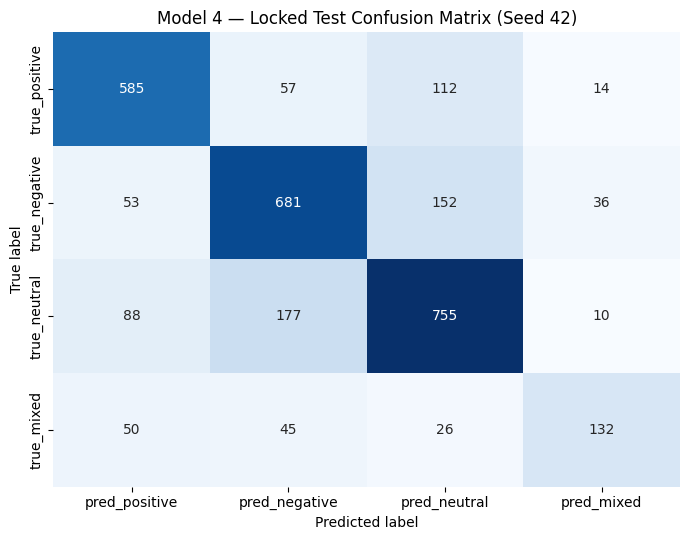

In [9]:
# Cell 9 — Reference-seed class and evidence diagnostics
reference = seed_outputs[REFERENCE_SEED]
print(f'Reference seed: {REFERENCE_SEED}')
display(seed_reports[REFERENCE_SEED].round(4))
display(seed_confusions[REFERENCE_SEED])

diagnostic_rows = []
for label in LABELS:
    mask = y_true == label
    probabilities = reference['probabilities'][mask]
    evidence = reference['evidence_predictions'][mask]
    diagnostic_rows.append({
        'true_class': LABEL_NAMES[label],
        'support': int(mask.sum()),
        'mean_positive_probability': float(probabilities[:, 0].mean()),
        'mean_negative_probability': float(probabilities[:, 1].mean()),
        'positive_head_on_rate': float(evidence[:, 0].mean()),
        'negative_head_on_rate': float(evidence[:, 1].mean()),
        'both_heads_on_rate': float(np.mean(np.all(evidence == 1, axis=1)))
    })
mechanism_df = pd.DataFrame(diagnostic_rows)
mechanism_df.to_csv(OUTPUT_DIR / 'FINAL_reference_seed_evidence_diagnostics.csv', index=False)
display(mechanism_df.round(4))

plt.figure(figsize=(7, 5.5))
sns.heatmap(seed_confusions[REFERENCE_SEED], annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f'Model 4 — Locked Test Confusion Matrix (Seed {REFERENCE_SEED})')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / f'FINAL_confusion_matrix_seed_{REFERENCE_SEED}.png', dpi=200, bbox_inches='tight')
plt.show()

In [10]:
# Cell 10 — Save final paper-ready summary and provenance
seed_results.to_csv(OUTPUT_DIR / 'FINAL_test_seed_results.csv', index=False)
mean_std.to_csv(OUTPUT_DIR / 'FINAL_test_mean_std.csv')

final_record = {
    'model': 'M4 Dual-polarity XLM-R',
    'split': 'locked_final_test',
    'n_test': int(len(test_df)),
    'seeds': RUN_SEEDS,
    'reference_seed_for_diagnostics': REFERENCE_SEED,
    'per_seed': seed_results.to_dict(orient='records'),
    'mean': {metric: float(mean_std.loc[metric, 'mean']) for metric in metric_columns},
    'sample_std': {metric: float(mean_std.loc[metric, 'std']) for metric in metric_columns},
    'split_sha256': EXPECTED_SPLIT_SHA256,
    'raw_sha256': EXPECTED_RAW_SHA256,
    'max_length': MAX_LENGTH,
    'target_map': TARGET_MAP,
    'evidence_threshold': EVIDENCE_THRESHOLD,
    'loss_used_during_training': manifest['loss'],
    'validation_H4_supported': False
}
with open(OUTPUT_DIR / 'FINAL_test_metrics.json', 'w', encoding='utf-8') as handle:
    json.dump(final_record, handle, indent=2, ensure_ascii=False)

print('\nSaved files:')
for path in sorted(OUTPUT_DIR.iterdir()):
    print(' -', path.name)
print('\nDo not tune the 0.5 thresholds or revise H4 after viewing these results.')


Saved files:
 - FINAL_classification_report_seed_13.csv
 - FINAL_classification_report_seed_42.csv
 - FINAL_classification_report_seed_77.csv
 - FINAL_confusion_matrix_seed_13.csv
 - FINAL_confusion_matrix_seed_42.csv
 - FINAL_confusion_matrix_seed_42.png
 - FINAL_confusion_matrix_seed_77.csv
 - FINAL_reference_seed_evidence_diagnostics.csv
 - FINAL_test_mean_std.csv
 - FINAL_test_metrics.json
 - FINAL_test_predictions_seed_13.csv
 - FINAL_test_predictions_seed_42.csv
 - FINAL_test_predictions_seed_77.csv
 - FINAL_test_seed_results.csv

Do not tune the 0.5 thresholds or revise H4 after viewing these results.


## What to keep after the run

Save the Kaggle version and retain the complete `bnsentmix_model4_final_test` folder. Keep all three prediction files and the reference-seed evidence diagnostic table. These outputs show whether true mixed samples activate both polarity heads and support the paper's mechanism analysis.